In [1]:
import numpy as np
import matplotlib.pyplot as plt
from session_data import *
from visualize import *
from antenna_array import *

session_dir = Path("../data/2025-11-16/rotation_80_direct")
session = SessionData.from_directory(session_dir)
session.load_all_router_batches()
print(session.summary())

channel_data = np.zeros((1, 16), dtype=np.complex128)

for dp in session.data_points:
    # Check if router batch is loaded
    if dp.router_batch is None:
        continue
        
    csi_data = dp.router_batch.csi_processed_data
    
    # Check if CSI data is not empty and has the right shape
    if csi_data.size == 0 or len(csi_data.shape) < 2:
        continue
    
    channel_data = np.vstack((channel_data, csi_data))

num_samples = channel_data.shape[0] - 1
valid_antennas = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 13, 21, 23, 25, 27]


num_samples = int(np.shape(channel_data)[0] / 10)
theta_vals = np.linspace(-80, 80, num_samples)
theta_vals = np.deg2rad(theta_vals)

# Create antenna arrays for each sample
spacing = 0.58 * 58.32 / 60.48
antenna_arrays = [AntennaArray() for _ in range(num_samples)]
antenna_arrays_real = [AntennaArray() for _ in range(num_samples)]
for i in range(num_samples):
    averaged_channel_data = np.mean(channel_data[i*10:(i+1)*10, :], axis=0)

    for antenna in range(32):
        if antenna not in valid_antennas:
            continue
        antenna_arrays[i].add_element(ordering_sets[antenna, 0]*spacing - np.sign(ordering_sets[antenna, 0])*spacing/2, 
            0, ordering_sets[antenna, 1]*spacing - np.sign(ordering_sets[antenna, 1])*spacing/2)
        antenna_arrays_real[i].add_element(ordering_sets[antenna, 0]*spacing - np.sign(ordering_sets[antenna, 0])*spacing/2, 
            0, ordering_sets[antenna, 1]*spacing - np.sign(ordering_sets[antenna, 1])*spacing/2)

    w = antenna_arrays[i].get_conjugate_beamformer(az=theta_vals[i], el=0)
    antenna_arrays[i].set_weights(w)
    antenna_arrays_real[i].set_weights(np.conjugate(averaged_channel_data))

Session: session_130954
Start: 2025-11-16 13:09:54.406331
End: 2025-11-16 13:22:26.440133
Duration: 752.0 seconds
Total Samples: 161
Data Points: 161
Images: 161



/home/kanishka/miniconda3/lib/python3.13/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/kanishka/miniconda3/lib/python3.13/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


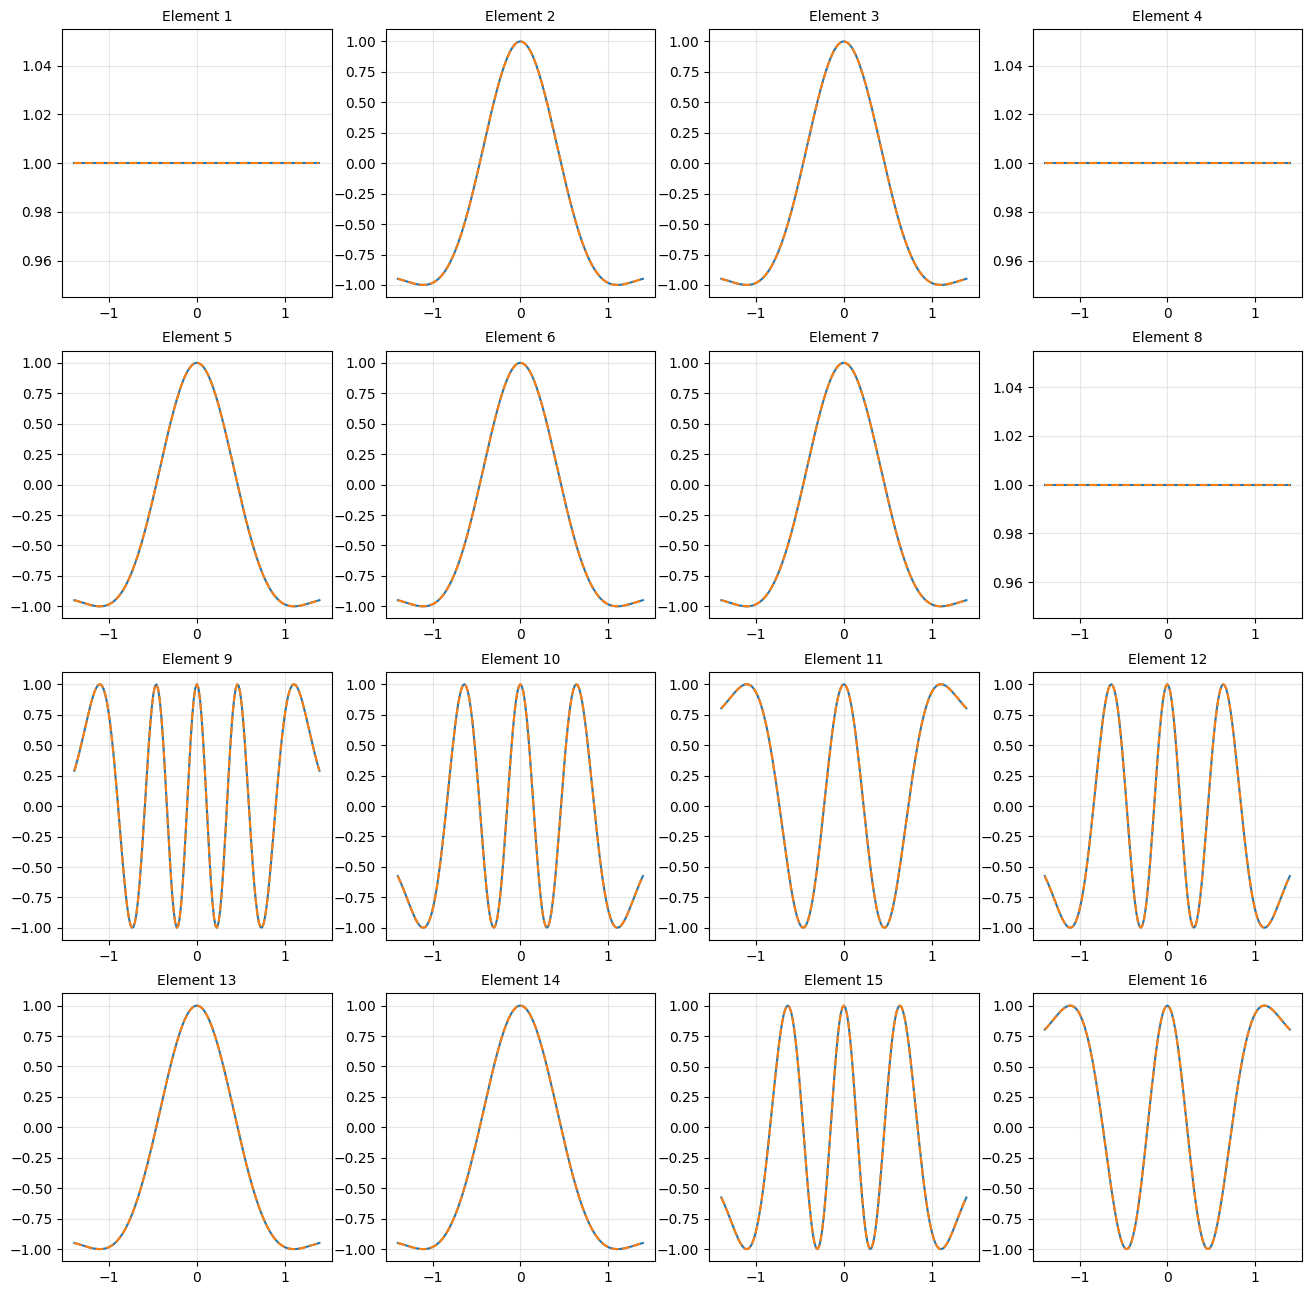

In [7]:
fig = plt.figure(figsize=(16, 16))

AF = np.zeros((num_samples, 16), dtype=np.complex128)
AF_real = np.zeros((num_samples, 16), dtype=np.complex128)

for i in range(num_samples):
    AF[i, :] = antenna_arrays[i].get_array_response(theta_vals[i], 0)
    AF_real[i, :] = antenna_arrays_real[i].get_array_response(theta_vals[i], 0)

# Plot first 16 elements
for idx in range(16):
    ax = plt.subplot(4, 4, idx + 1)
    
    # Plot
    ax.plot(theta_vals, AF[:, idx], linewidth=1.5, label='Ideal')
    ax.plot(theta_vals, AF_real[:, idx], linewidth=1.5, label='Real', linestyle='--')
    
    # Configure polar plot
    ax.set_title(f'Element {idx+1}', fontsize=10)
    ax.grid(True, alpha=0.3)
